In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import t
from statsmodels.stats.proportion import proportion_confint
from matplotlib.ticker import PercentFormatter

In [2]:
df = pd.read_csv("/project/data/hotel-booking-demand/hotel_bookings.csv")

In [111]:
def grouped_barplot(df, feature, target, groups, ci=95):

    summary = (
        df.groupby([feature, groups], dropna=False)
        .agg(
            n=(target, 'size'),
            k=(target, 'sum')
        )
        .assign(prop=lambda d: d['k'] / d['n'])
    )

    summary[['lower', 'upper']] = summary.apply(
        lambda r: proportion_confint(
            r['k'],
            r['n'],
            method='wilson',
            alpha=1 - ci / 100
        ),
        axis=1,
        result_type='expand'
    )

    plot_data = summary.reset_index()
    hue_order = plot_data[groups].drop_duplicates()

    ax = sns.barplot(
        data=summary,
        x='prop',
        y=feature,
        hue=groups,
        hue_order=hue_order,
        order=plot_data[feature].drop_duplicates(),
        errorbar=None
    )

    for container, hue in zip(ax.containers[:len(hue_order)], hue_order):
        for bar, segment in zip(
            container,
            plot_data.loc[plot_data[groups] == hue, feature].drop_duplicates()
        ):
            if (segment, hue) not in summary.index:
                continue

            row = summary.loc[(segment, hue)]

            ax.errorbar(
                x=bar.get_width(),
                y=bar.get_y() + bar.get_height() / 2,
                xerr=[[
                    row['prop'] - row['lower']
                ], [
                    row['upper'] - row['prop']
                ]],
                fmt='none',
                color='#444444',
                capsize=0
            )

    
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_xlim(0, 1)

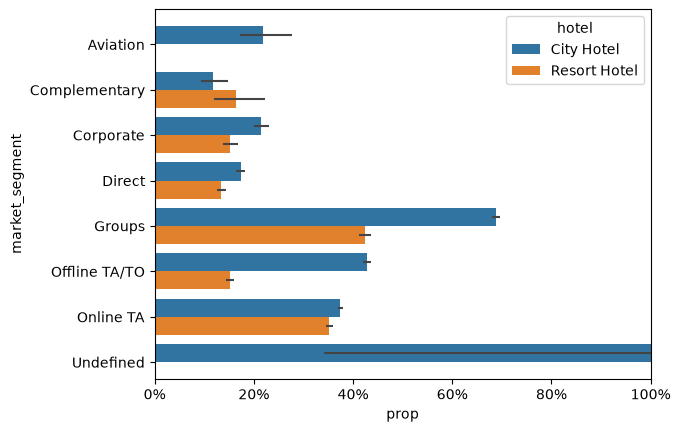

In [112]:
grouped_barplot(df, 'market_segment', 'is_canceled', 'hotel')

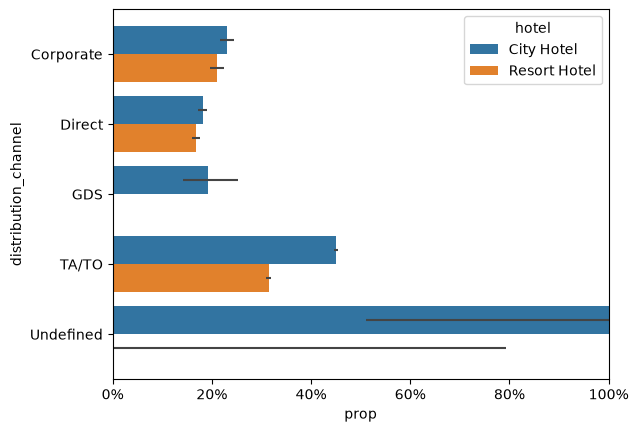

In [113]:
grouped_barplot(df, 'distribution_channel', 'is_canceled', 'hotel')